# ISYE7406 Project Midterm Report: Data Preparation & EDA
**Team 51 · Jacob Schroeder**

This notebook covers **Section 2.2 (Data Description)** and **Section 2.3 (Exploratory Data Analysis)**, and writes an analysis-ready dataset (`tmdb_clean.csv`) for Section 5.

**Required files** (put in `DATA_DIR`, default `./data`):
- `tmdb_5000_movies.csv`, `tmdb_5000_credits.csv` (Kaggle: tmdb/tmdb-movie-metadata)
- `the_oscar_award.csv` (Kaggle: unanimad/the-oscar-award), optional; the awards section is skipped if absent

Figures are shown inline and also saved to `OUT_DIR/figures`; tables are saved to `OUT_DIR/tables` as CSV + LaTeX.

**Install if needed:** `pip install pandas numpy scipy statsmodels seaborn matplotlib jinja2`

## 0. Setup & configuration

In [1]:
%matplotlib inline
import json
import re
import unicodedata
import warnings
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from statsmodels.nonparametric.smoothers_lowess import lowess
from statsmodels.stats.proportion import proportion_confint
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="paper", font_scale=1.15)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight"})
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

# ---- paths & analysis window (edit these) ----
DATA_DIR = Path("data")
OUT_DIR = Path("outputs")
MIN_YEAR, MAX_YEAR = 1960, 2017      # MIN_YEAR must be >= 1960 (CPI table start)

In [2]:
BASE_YEAR = 2017            # inflation-adjust everything to 2017 dollars
MIN_DOLLARS = 10_000        # budgets/revenues below this are treated as data errors
OSCAR_YEAR_TOL = 1          # match Oscar film year to TMDB release year +/- this
ERA_ORDER = ["<=1979", "1980s", "1990s", "2000s", "2010s"]

# US CPI-U annual averages (1982-84 = 100). Entered from memory -- verify against
# BLS (https://www.bls.gov/cpi/) before submitting, and cite BLS in the report.
CPI = {
    1960: 29.6, 1961: 29.9, 1962: 30.2, 1963: 30.6, 1964: 31.0, 1965: 31.5,
    1966: 32.4, 1967: 33.4, 1968: 34.8, 1969: 36.7, 1970: 38.8, 1971: 40.5,
    1972: 41.8, 1973: 44.4, 1974: 49.3, 1975: 53.8, 1976: 56.9, 1977: 60.6,
    1978: 65.2, 1979: 72.6, 1980: 82.4, 1981: 90.9, 1982: 96.5, 1983: 99.6,
    1984: 103.9, 1985: 107.6, 1986: 109.6, 1987: 113.6, 1988: 118.3, 1989: 124.0,
    1990: 130.7, 1991: 136.2, 1992: 140.3, 1993: 144.5, 1994: 148.2, 1995: 152.4,
    1996: 156.9, 1997: 160.5, 1998: 163.0, 1999: 166.6, 2000: 172.2, 2001: 177.1,
    2002: 179.9, 2003: 184.0, 2004: 188.9, 2005: 195.3, 2006: 201.6, 2007: 207.3,
    2008: 215.3, 2009: 214.5, 2010: 218.1, 2011: 224.9, 2012: 229.6, 2013: 233.0,
    2014: 236.7, 2015: 237.0, 2016: 240.0, 2017: 245.1,
}

LOG_LINES = []

assert MIN_YEAR >= min(CPI) and MAX_YEAR <= max(CPI), 'year range outside CPI table'

> **Check before submitting:** the CPI-U values above were entered from memory. Verify against BLS (https://www.bls.gov/cpi/) and cite BLS in the report.

## 1. Helper functions

In [3]:
LOG_LINES = []


def say(msg=""):
    print(msg)
    LOG_LINES.append(str(msg))


def header(msg):
    say("\n" + "=" * 78)
    say(msg)
    say("=" * 78)


class Out:
    def __init__(self, root):
        self.root = Path(root)
        self.fig = self.root / "figures"
        self.tab = self.root / "tables"
        self.fig.mkdir(parents=True, exist_ok=True)
        self.tab.mkdir(parents=True, exist_ok=True)

    def savefig(self, name):
        plt.tight_layout()
        plt.savefig(self.fig / f"{name}.png")
        plt.show()
        say(f"  [figure] {name}.png")

    def savetab(self, df, name, index=True, float_format="%.3f"):
        df.to_csv(self.tab / f"{name}.csv", index=index, float_format=float_format)
        try:  # LaTeX version (needs jinja2 on newer pandas); skip quietly if absent
            df.to_latex(self.tab / f"{name}.tex", index=index, float_format=lambda v: float_format % v)
        except Exception:
            pass
        say(f"  [table]  {name}.csv")


def parse_json(x):
    try:
        return json.loads(x)
    except Exception:
        return []


def norm_title(t):
    t = unicodedata.normalize("NFKD", str(t)).encode("ascii", "ignore").decode()
    t = t.lower().replace("&", " and ")
    t = re.sub(r"[^a-z0-9 ]", " ", t)
    t = re.sub(r"\s+", " ", t).strip()
    return re.sub(r"^(the|a|an) ", "", t)


def era_label(y):
    return "<=1979" if y < 1980 else f"{(int(y) // 10) * 10}s"


def fisher_ci(r, n, alpha=0.05):
    if n < 4 or abs(r) >= 1:
        return np.nan, np.nan
    z, se, zc = np.arctanh(r), 1 / np.sqrt(n - 3), stats.norm.ppf(1 - alpha / 2)
    return np.tanh(z - zc * se), np.tanh(z + zc * se)


def partial_corr(df, x, y, controls):
    d = df[[x, y] + controls].dropna()
    Z = np.column_stack([np.ones(len(d))] + [d[c].values for c in controls])
    rx = d[x].values - Z @ np.linalg.lstsq(Z, d[x].values, rcond=None)[0]
    ry = d[y].values - Z @ np.linalg.lstsq(Z, d[y].values, rcond=None)[0]
    r, p = stats.pearsonr(rx, ry)
    return r, p, len(d)


def scatter_lowess(ax, x, y, ylog=False, frac=0.5, color="#4C72B0"):
    d = pd.DataFrame({"x": x, "y": y}).dropna()
    ax.scatter(d.x, d.y, s=7, alpha=0.25, color=color, edgecolor="none")
    yy = np.log(d.y) if ylog else d.y
    sm = lowess(yy, d.x, frac=frac, return_sorted=True)
    ax.plot(sm[:, 0], np.exp(sm[:, 1]) if ylog else sm[:, 1], lw=2.2, color="crimson")
    if ylog:
        ax.set_yscale("log")


out = Out(OUT_DIR)

## 2. Load data & engineer features
Merges movies and credits on movie id, then converts the nested JSON into cast size, crew size, crew-by-department counts, genres, etc.

In [4]:
def load_and_engineer(data_dir):
    header("LOADING DATA")
    movies = pd.read_csv(data_dir / "tmdb_5000_movies.csv")
    credits = pd.read_csv(data_dir / "tmdb_5000_credits.csv")
    say(f"movies:  {movies.shape}   credits: {credits.shape}")

    credits = credits.rename(columns={"movie_id": "id"}).drop(columns=["title"], errors="ignore")
    df = movies.merge(credits, on="id", how="inner", validate="one_to_one").reset_index(drop=True)
    say(f"merged on movie id: {df.shape}")

    # ---- cast / crew engineering (nested JSON -> numeric features) ----
    cast_l = df["cast"].map(parse_json)
    crew_l = df["crew"].map(parse_json)
    df["cast_size"] = cast_l.map(len)
    df["crew_size"] = crew_l.map(len)
    dept = pd.DataFrame([Counter(c.get("department", "Unknown") for c in cl) for cl in crew_l]).fillna(0).astype(int)
    dept.columns = ["crew_" + re.sub(r"[^A-Za-z0-9]+", "_", c).strip("_").lower() for c in dept.columns]
    df = pd.concat([df, dept], axis=1)
    df["crew_departments"] = (dept > 0).sum(axis=1)

    # ---- other parsed features ----
    df["genres_list"] = df["genres"].map(lambda s: [g["name"] for g in parse_json(s)])
    df["n_genres"] = df["genres_list"].map(len)
    df["primary_genre"] = df["genres_list"].map(lambda g: g[0] if g else "Unknown")
    df["n_prod_companies"] = df["production_companies"].map(lambda s: len(parse_json(s)))
    df["is_english"] = (df["original_language"] == "en").astype(int)

    # ---- dates ----
    df["release_date"] = pd.to_datetime(df["release_date"], errors="coerce")
    df["release_year"] = df["release_date"].dt.year
    df["release_month"] = df["release_date"].dt.month
    return df


full = load_and_engineer(DATA_DIR)
full[['title', 'release_year', 'budget', 'revenue', 'cast_size', 'crew_size', 'primary_genre']].head()


LOADING DATA
movies:  (4803, 20)   credits: (4803, 4)
merged on movie id: (4803, 22)


,title,release_year,budget,revenue,cast_size,crew_size,primary_genre
0,Avatar,2009.0,237000000,2787965087,83,153,Action
1,Pirates of the Caribbean: At World's End,2007.0,300000000,961000000,34,32,Adventure
2,Spectre,2015.0,245000000,880674609,83,155,Action
3,The Dark Knight Rises,2012.0,250000000,1084939099,158,217,Action
4,John Carter,2012.0,260000000,284139100,27,132,Action


## 3. Cleaning funnel & inflation adjustment
Budgets/revenues below `MIN_DOLLARS` are treated as missing (TMDB uses 0 for unknown). All dollar values are also converted to 2017 USD with CPI-U.

In [5]:
def clean(df, min_year, max_year, out):
    header("CLEANING FUNNEL")
    funnel = [("Raw movies x credits (joined)", len(df))]

    d = df[df["status"] == "Released"]
    funnel.append(("Status == Released", len(d)))
    d = d[d["release_year"].between(min_year, max_year)]
    funnel.append((f"Release year in [{min_year}, {max_year}]", len(d)))
    d = d[(d["budget"] >= MIN_DOLLARS) & (d["revenue"] >= MIN_DOLLARS)]
    funnel.append((f"Budget and revenue >= ${MIN_DOLLARS:,}", len(d)))
    d = d[d["runtime"] > 0]
    funnel.append(("Runtime > 0", len(d)))
    d = d[(d["cast_size"] > 0) & (d["crew_size"] > 0)]
    funnel.append(("Non-empty cast and crew lists", len(d)))

    ft = pd.DataFrame(funnel, columns=["Step", "Films remaining"])
    ft["Dropped"] = -ft["Films remaining"].diff().fillna(0).astype(int)
    say(ft.to_string(index=False))
    out.savetab(ft, "cleaning_funnel", index=False, float_format="%.0f")

    an = d.copy()
    an["cpi_factor"] = an["release_year"].map(lambda y: CPI[BASE_YEAR] / CPI[int(y)])
    an["budget_real"] = an["budget"] * an["cpi_factor"]
    an["revenue_real"] = an["revenue"] * an["cpi_factor"]
    an["roi"] = an["revenue_real"] / an["budget_real"]
    for c in ["budget", "revenue", "budget_real", "revenue_real", "roi", "cast_size", "crew_size"]:
        an[f"ln_{c}"] = np.log(an[c])
    an["era"] = pd.Categorical(an["release_year"].map(era_label), categories=ERA_ORDER, ordered=True)
    return an


an = clean(full, MIN_YEAR, MAX_YEAR, out)
an[['title', 'release_year', 'era', 'budget_real', 'revenue_real', 'roi']].head()


CLEANING FUNNEL
                         Step  Films remaining  Dropped
Raw movies x credits (joined)             4803        0
           Status == Released             4795        8
 Release year in [1960, 2017]             4722       73
Budget and revenue >= $10,000             3143     1579
                  Runtime > 0             3143        0
Non-empty cast and crew lists             3139        4
  [table]  cleaning_funnel.csv


,title,release_year,era,budget_real,revenue_real,roi
0,Avatar,2009.0,2000s,2.708098e+08,3.185689e+09,11.763566
1,Pirates of the Caribbean: At World's End,2007.0,2000s,3.547033e+08,1.136233e+09,3.203333
2,Spectre,2015.0,2010s,2.533734e+08,9.107736e+08,3.594590
3,The Dark Knight Rises,2012.0,2010s,2.668772e+08,1.158182e+09,4.339756
4,John Carter,2012.0,2010s,2.775523e+08,3.033210e+08,1.092843


## 4. Merge Oscar nomination / win data
Matched on normalised title and release year (±`OSCAR_YEAR_TOL` year).

In [6]:
def merge_oscars(an, data_dir, out):
    header("MERGING OSCAR DATA")
    path = data_dir / "the_oscar_award.csv"
    if not path.exists():
        say(f"  !! {path} not found -- skipping awards analysis.")
        return an, False

    os_ = pd.read_csv(path)
    yr_col = "year_film" if "year_film" in os_.columns else "year"
    os_ = os_.dropna(subset=["film"]).copy()
    os_["winner"] = os_["winner"].astype(str).str.lower().isin(["true", "1", "yes"])
    os_["key"] = os_["film"].map(norm_title)
    say(f"Oscar rows (with a film): {len(os_):,}   years {os_[yr_col].min()}-{os_[yr_col].max()}")

    agg = (os_.groupby(["key", yr_col])
              .agg(n_noms=("winner", "size"), n_wins=("winner", "sum"),
                   categories=("category", lambda s: "; ".join(sorted(set(s)))))
              .reset_index())
    lookup = {(r["key"], int(r[yr_col])): r for _, r in agg.iterrows()}

    keys = an["title"].map(norm_title)
    hits, matched_keys = [], set()
    for k, y in zip(keys, an["release_year"].astype(int)):
        rec = None
        for dy in sorted(range(-OSCAR_YEAR_TOL, OSCAR_YEAR_TOL + 1), key=abs):
            rec = lookup.get((k, y + dy))
            if rec is not None:
                matched_keys.add((k, y + dy))
                break
        hits.append(rec)
    an["n_noms"] = [int(h["n_noms"]) if h is not None else 0 for h in hits]
    an["n_wins"] = [int(h["n_wins"]) if h is not None else 0 for h in hits]
    an["oscar_categories"] = [h["categories"] if h is not None else "" for h in hits]
    an["nominated"] = (an["n_noms"] > 0).astype(int)
    an["won"] = (an["n_wins"] > 0).astype(int)

    # sanity check: Oscar films in our window that did not match a TMDB analysis film
    in_window = agg[agg[yr_col].between(an["release_year"].min(), an["release_year"].max())]
    un = in_window[[(k, int(y)) not in matched_keys for k, y in zip(in_window["key"], in_window[yr_col])]]
    ex = os_.drop_duplicates("key").set_index("key")["film"]
    un = un.assign(film=un["key"].map(ex))[["film", yr_col, "n_noms", "n_wins"]]
    un.to_csv(out.tab / "oscar_unmatched_check.csv", index=False)
    say(f"Oscar-nominated films in window: {len(in_window):,}; matched to analysis set: {len(matched_keys):,}")
    say("  (Unmatched films are expected: TMDB-5000 is a subset and we dropped films lacking budget/revenue.")
    say("   Review tables/oscar_unmatched_check.csv for title-format mismatches, e.g. subtitles or punctuation.)")
    say(f"Analysis films nominated: {an['nominated'].sum()}  |  won >=1 award: {an['won'].sum()}")
    return an, True


an, has_awards = merge_oscars(an, DATA_DIR, out)


MERGING OSCAR DATA
Oscar rows (with a film): 10,877   years 1927-2025
Oscar-nominated films in window: 3,016; matched to analysis set: 747
  (Unmatched films are expected: TMDB-5000 is a subset and we dropped films lacking budget/revenue.
   Review tables/oscar_unmatched_check.csv for title-format mismatches, e.g. subtitles or punctuation.)
Analysis films nominated: 747  |  won >=1 award: 300


## 5. Section 2.2: Data Description


SECTION 2.2  DATA DESCRIPTION
  [table]  data_dictionary.csv

Full joined dataset: 4,803 films x 44 columns
Analysis dataset:    3,139 films (1960.0-2016.0)

Missing / zero values among released films (pre-cleaning), %:
                       pct_missing_or_zero
budget (0 = missing)                 21.52
revenue (0 = missing)                29.61
runtime                               0.75
release_date                          0.02
cast list empty                       0.86
crew list empty                       0.54
homepage                             64.36
tagline                              17.48
  [table]  missingness.csv

Share of films with usable budget & revenue, by era (selection-bias check):
        films  usable  pct_usable
era                              
<=1979    180     139        77.2
1980s     278     204        73.4
1990s     778     535        68.8
2000s    2044    1324        64.8
2010s    1441     941        65.3
  [table]  usable_by_era.csv

Summary statistics (

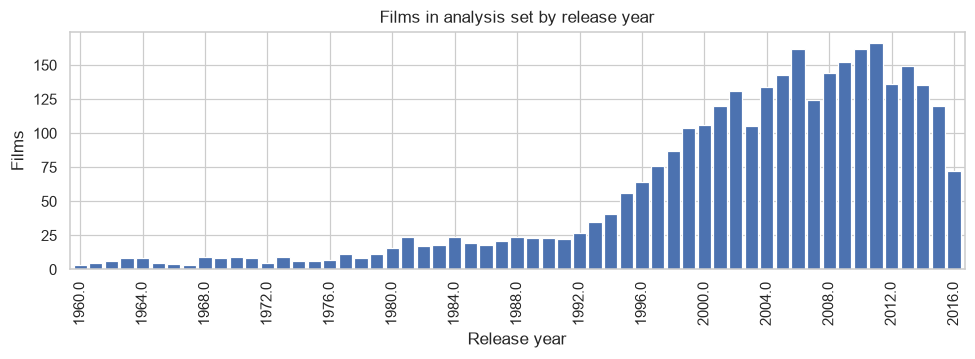

  [figure] fig_films_per_year.png


In [7]:
def data_description(full, an, out, has_awards):
    header("SECTION 2.2  DATA DESCRIPTION")

    dd = [
        ("budget / budget_real", "Production budget, nominal USD / 2017 USD (CPI-adjusted)", "TMDB movies"),
        ("revenue / revenue_real", "Worldwide box office, nominal USD / 2017 USD", "TMDB movies"),
        ("roi", "revenue_real / budget_real", "Engineered"),
        ("release_year, era", "Year and era (<=1979, 1980s, ..., 2010s) of release", "TMDB movies"),
        ("runtime", "Runtime in minutes", "TMDB movies"),
        ("vote_average, vote_count", "TMDB user rating and number of ratings", "TMDB movies"),
        ("popularity", "TMDB popularity score", "TMDB movies"),
        ("primary_genre, n_genres", "First-listed genre and number of genres", "Parsed from JSON"),
        ("n_prod_companies, is_english", "Number of production companies; English-language flag", "Parsed from JSON"),
        ("cast_size", "Number of credited cast members", "Parsed from credits JSON"),
        ("crew_size", "Number of credited crew members", "Parsed from credits JSON"),
        ("crew_<department>", "Crew counts by department (Production, Sound, Art, ...)", "Parsed from credits JSON"),
        ("crew_departments", "Number of distinct crew departments credited", "Parsed from credits JSON"),
    ]
    if has_awards:
        dd += [("n_noms, n_wins", "Oscar nominations / wins per film (all categories)", "Oscar dataset (merged)"),
               ("nominated, won", "1 if film has >=1 nomination / >=1 win", "Engineered")]
    out.savetab(pd.DataFrame(dd, columns=["Variable", "Description", "Source"]), "data_dictionary", index=False)

    # --- sizes ---
    say(f"\nFull joined dataset: {len(full):,} films x {full.shape[1]} columns")
    say(f"Analysis dataset:    {len(an):,} films ({an['release_year'].min()}-{an['release_year'].max()})")

    # --- missing / zero values (pre-cleaning) ---
    rel = full[full["status"] == "Released"]
    miss = pd.DataFrame({
        "pct_missing_or_zero": [
            (rel["budget"].fillna(0) <= 0).mean() * 100,
            (rel["revenue"].fillna(0) <= 0).mean() * 100,
            (rel["runtime"].fillna(0) <= 0).mean() * 100,
            rel["release_date"].isna().mean() * 100,
            (rel["cast_size"] == 0).mean() * 100,
            (rel["crew_size"] == 0).mean() * 100,
            rel["homepage"].isna().mean() * 100,
            rel["tagline"].isna().mean() * 100,
        ]}, index=["budget (0 = missing)", "revenue (0 = missing)", "runtime", "release_date",
                   "cast list empty", "crew list empty", "homepage", "tagline"])
    say("\nMissing / zero values among released films (pre-cleaning), %:")
    say(miss.round(2).to_string())
    out.savetab(miss, "missingness")

    # selection check: share of films with usable budget AND revenue, by era
    r2 = rel[rel["release_year"].between(an["release_year"].min(), an["release_year"].max())].copy()
    r2["era"] = r2["release_year"].map(era_label)
    r2["usable"] = ((r2["budget"] >= MIN_DOLLARS) & (r2["revenue"] >= MIN_DOLLARS)).astype(int)
    sel = r2.groupby("era")["usable"].agg(films="size", usable="sum", pct_usable="mean")
    sel["pct_usable"] *= 100
    sel = sel.reindex([e for e in ERA_ORDER if e in sel.index])
    say("\nShare of films with usable budget & revenue, by era (selection-bias check):")
    say(sel.round(1).to_string())
    out.savetab(sel, "usable_by_era")

    # --- summary statistics ---
    nums = ["budget", "budget_real", "revenue", "revenue_real", "roi", "runtime", "vote_average",
            "vote_count", "popularity", "cast_size", "crew_size", "crew_departments", "n_genres",
            "n_prod_companies"]
    desc = an[nums].describe().T
    desc["skew"] = an[nums].skew()
    say("\nSummary statistics (analysis set):")
    say(desc.round(2).to_string())
    out.savetab(desc, "summary_statistics", float_format="%.2f")

    # --- crew department breakdown ---
    dept_cols = [c for c in an.columns if c.startswith("crew_") and c not in ("crew_size", "crew_departments")]
    dm = an[dept_cols].mean().sort_values(ascending=False).to_frame("mean_crew_count")
    say("\nMean crew count by department:")
    say(dm.round(2).to_string())
    out.savetab(dm, "crew_department_means")

    # --- 2.2 figure: sample size per year ---
    fig, ax = plt.subplots(figsize=(9, 3.4))
    an["release_year"].value_counts().sort_index().plot(kind="bar", ax=ax, color="#4C72B0", width=0.85)
    ax.set_xlabel("Release year")
    ax.set_ylabel("Films")
    ax.set_title("Films in analysis set by release year")
    ax.set_xticks(ax.get_xticks()[::4])
    out.savefig("fig_films_per_year")


data_description(full, an, out, has_awards)

## 6. Section 2.3: Exploratory Data Analysis

### 6.1 Univariate distributions


2.3  EDA - UNIVARIATE DISTRIBUTIONS


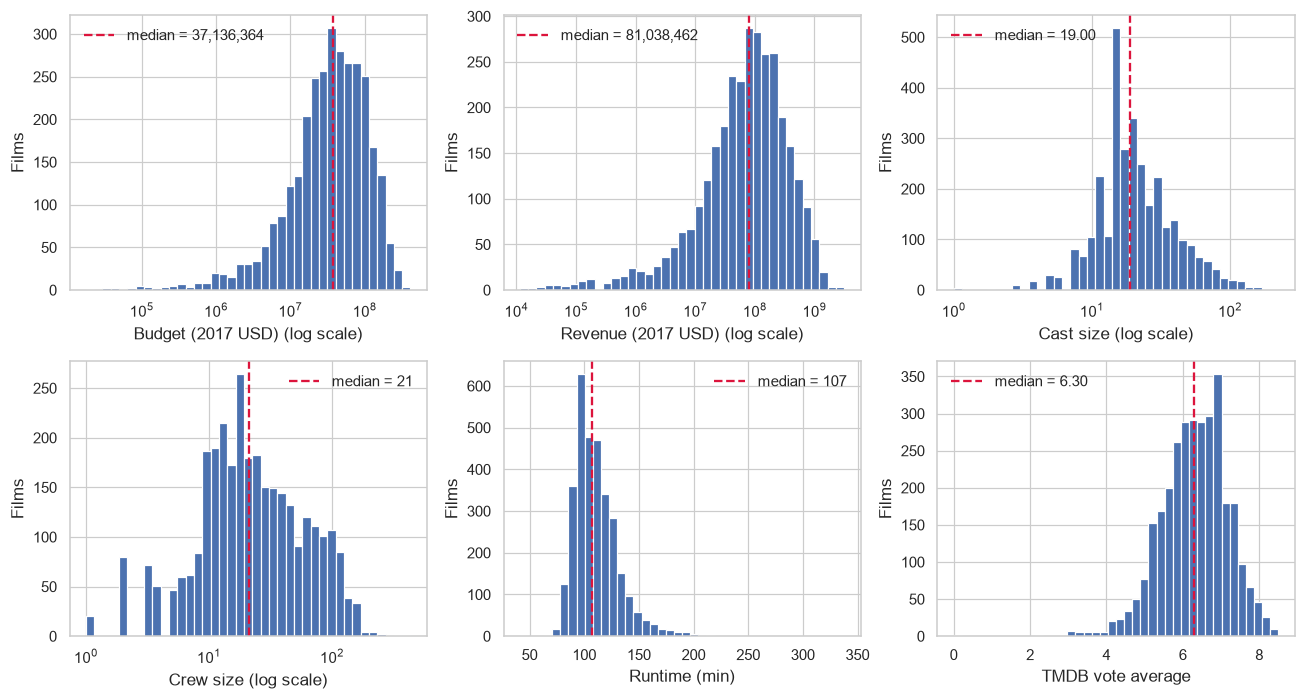

  [figure] fig_distributions.png
  Skewness (raw -> log): budget_real: 1.7 -> -1.29, revenue_real: 3.9 -> -1.25, cast_size: 3.0 -> 0.24, crew_size: 2.3 -> -0.26


In [8]:
def eda_distributions(an, out):
    header("2.3  EDA - UNIVARIATE DISTRIBUTIONS")
    specs = [("budget_real", "Budget (2017 USD)", True), ("revenue_real", "Revenue (2017 USD)", True),
             ("cast_size", "Cast size", True), ("crew_size", "Crew size", True),
             ("runtime", "Runtime (min)", False), ("vote_average", "TMDB vote average", False)]
    fig, axes = plt.subplots(2, 3, figsize=(12, 6.5))
    for ax, (c, lab, logx) in zip(axes.ravel(), specs):
        x = an[c].dropna()
        bins = np.logspace(np.log10(x.min()), np.log10(x.max()), 40) if logx else 40
        ax.hist(x, bins=bins, color="#4C72B0", edgecolor="white")
        if logx:
            ax.set_xscale("log")
        ax.axvline(x.median(), color="crimson", ls="--", lw=1.5, label=f"median = {x.median():,.0f}" if x.median() > 20 else f"median = {x.median():.2f}")
        ax.set_xlabel(lab + (" (log scale)" if logx else ""))
        ax.set_ylabel("Films")
        ax.legend(frameon=False)
    out.savefig("fig_distributions")
    say("  Skewness (raw -> log): " + ", ".join(
        f"{c}: {an[c].skew():.1f} -> {np.log(an[c]).skew():.2f}"
        for c in ["budget_real", "revenue_real", "cast_size", "crew_size"]))


eda_distributions(an, out)

### 6.2 Time trends in budget, revenue, cast/crew size (RQ1)


2.3  EDA - TIME TRENDS (RQ1)


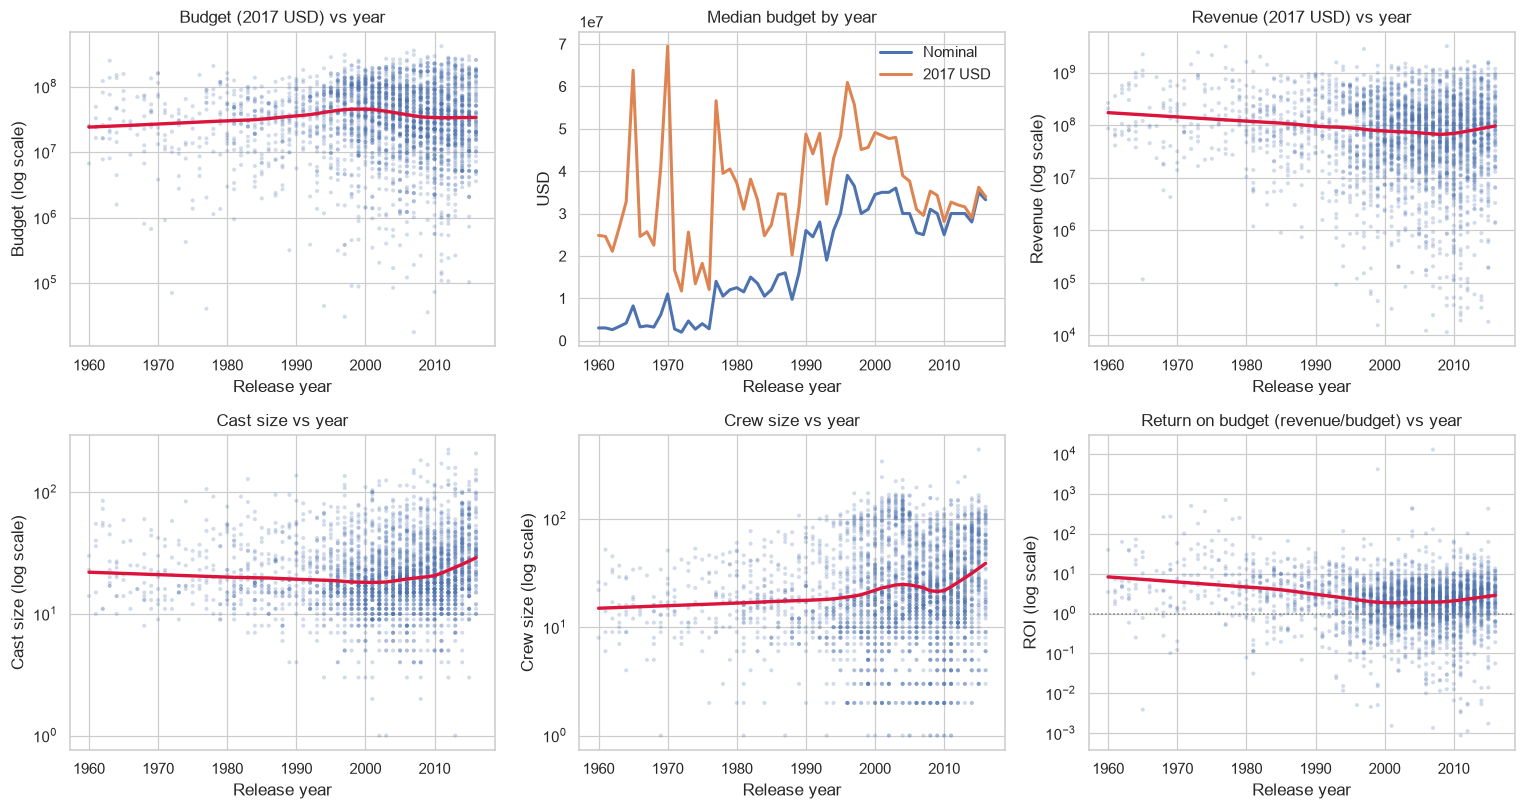

  [figure] fig_time_trends.png
        films  median_budget_nominal  median_budget_real  median_revenue_real  median_roi  pct_budget_ge_100M_real  median_cast  median_crew  median_runtime
era                                                                                                                                                         
<=1979    139              4000000.0         25970860.93         1.335695e+08        5.92                    11.51         20.0         16.0           121.0
1980s     204             13900000.0         29975565.77         9.062063e+07        3.97                     4.90         18.0         17.0           107.0
1990s     535             30000000.0         47493425.61         8.412849e+07        2.11                    18.13         18.0         17.0           108.0
2000s    1321             30000000.0         38925357.33         7.424868e+07        1.98                    16.65         18.0         22.0           105.0
2010s     940             3

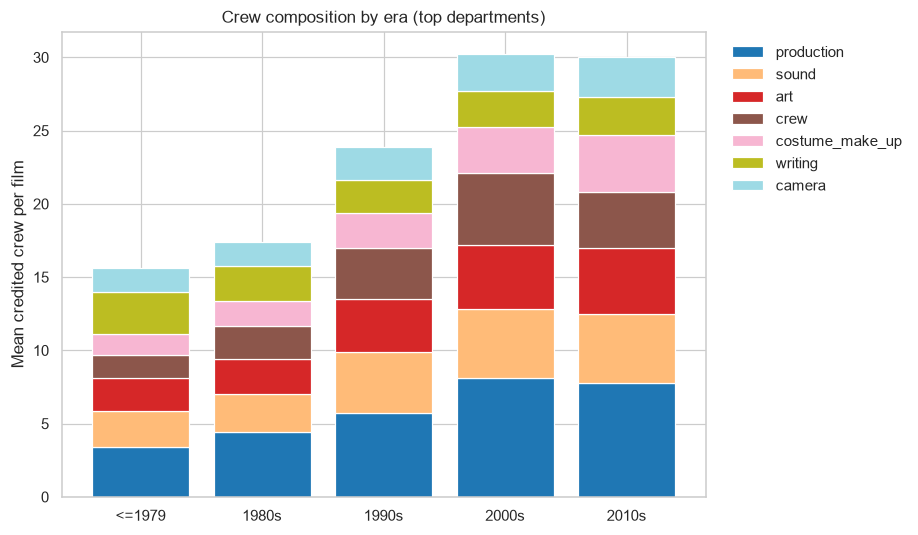

  [figure] fig_crew_composition_by_era.png


In [9]:
def eda_time_trends(an, out):
    header("2.3  EDA - TIME TRENDS (RQ1)")
    yr = an["release_year"]
    fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))

    scatter_lowess(axes[0, 0], yr, an["budget_real"], ylog=True)
    axes[0, 0].set_title("Budget (2017 USD) vs year")
    axes[0, 0].set_ylabel("Budget (log scale)")

    med = an.groupby("release_year")[["budget", "budget_real"]].median()
    axes[0, 1].plot(med.index, med["budget"], label="Nominal", lw=2)
    axes[0, 1].plot(med.index, med["budget_real"], label="2017 USD", lw=2)
    axes[0, 1].set_title("Median budget by year")
    axes[0, 1].set_ylabel("USD")
    axes[0, 1].legend(frameon=False)

    scatter_lowess(axes[0, 2], yr, an["revenue_real"], ylog=True)
    axes[0, 2].set_title("Revenue (2017 USD) vs year")
    axes[0, 2].set_ylabel("Revenue (log scale)")

    scatter_lowess(axes[1, 0], yr, an["cast_size"], ylog=True)
    axes[1, 0].set_title("Cast size vs year")
    axes[1, 0].set_ylabel("Cast size (log scale)")

    scatter_lowess(axes[1, 1], yr, an["crew_size"], ylog=True)
    axes[1, 1].set_title("Crew size vs year")
    axes[1, 1].set_ylabel("Crew size (log scale)")

    scatter_lowess(axes[1, 2], yr, an["roi"], ylog=True)
    axes[1, 2].axhline(1, color="grey", ls=":", lw=1)
    axes[1, 2].set_title("Return on budget (revenue/budget) vs year")
    axes[1, 2].set_ylabel("ROI (log scale)")
    for ax in axes.ravel():
        ax.set_xlabel("Release year")
    out.savefig("fig_time_trends")

    # era summary table
    g = an.groupby("era", observed=True)
    tab = pd.DataFrame({
        "films": g.size(),
        "median_budget_nominal": g["budget"].median(),
        "median_budget_real": g["budget_real"].median(),
        "median_revenue_real": g["revenue_real"].median(),
        "median_roi": g["roi"].median(),
        "pct_budget_ge_100M_real": g["budget_real"].apply(lambda s: (s >= 1e8).mean() * 100),
        "median_cast": g["cast_size"].median(),
        "median_crew": g["crew_size"].median(),
        "median_runtime": g["runtime"].median(),
    })
    say(tab.round(2).to_string())
    out.savetab(tab, "era_summary", float_format="%.2f")

    # Spearman trend tests vs year (monotonic time trends)
    rows = []
    for c in ["budget_real", "revenue_real", "roi", "cast_size", "crew_size"]:
        rho, p = stats.spearmanr(an["release_year"], an[c])
        rows.append((c, rho, p))
    tt = pd.DataFrame(rows, columns=["variable", "spearman_rho_vs_year", "p_value"]).set_index("variable")
    say("\nMonotonic trend vs release year:")
    say(tt.round(4).to_string())
    out.savetab(tt, "trend_tests", float_format="%.4f")

    # crew composition by era
    dept_cols = [c for c in an.columns if c.startswith("crew_") and c not in ("crew_size", "crew_departments")]
    top = an[dept_cols].mean().sort_values(ascending=False).head(7).index.tolist()
    comp = an.groupby("era", observed=True)[top].mean()
    ax = comp.plot(kind="bar", stacked=True, figsize=(8.5, 5), colormap="tab20", width=0.8)
    ax.set_ylabel("Mean credited crew per film")
    ax.set_xlabel("")
    ax.set_title("Crew composition by era (top departments)")
    ax.legend([c.replace("crew_", "") for c in top], frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.xticks(rotation=0)
    out.savefig("fig_crew_composition_by_era")


eda_time_trends(an, out)

### 6.3 Budget vs. revenue by era (RQ1)


2.3  EDA - BUDGET vs REVENUE BY ERA (RQ1)


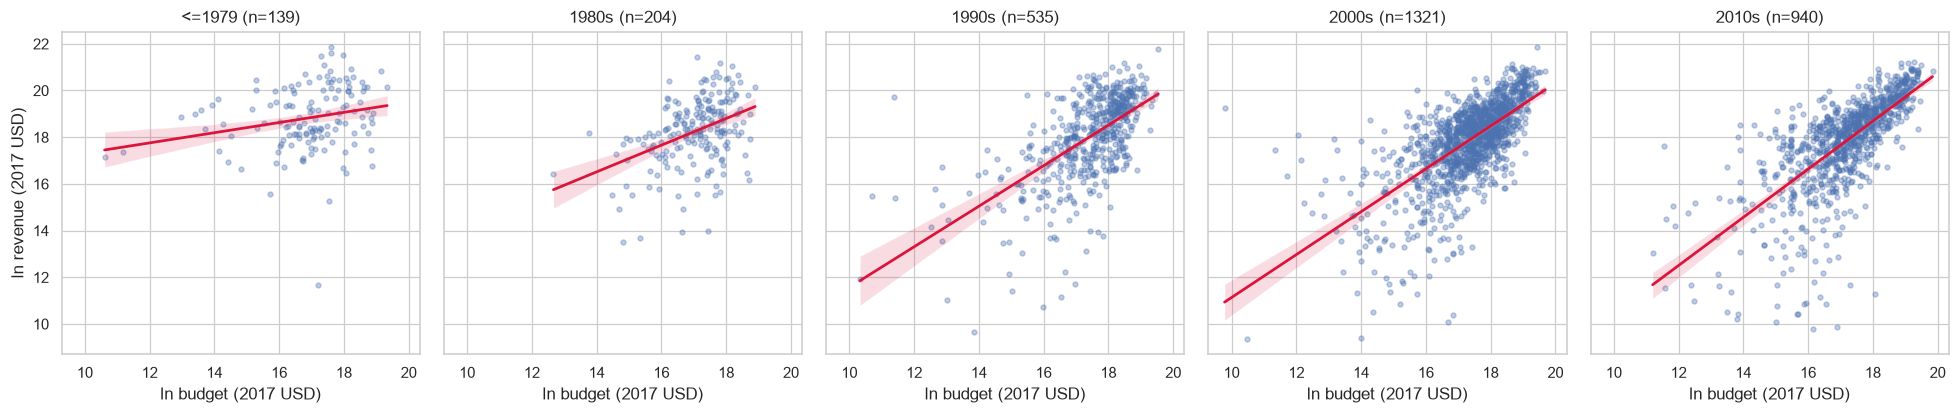

  [figure] fig_budget_revenue_by_era.png
           n  pearson_r  ci_lo  ci_hi  spearman_rho  ols_slope  slope_se  r_squared
era                                                                                
<=1979   139      0.225  0.061  0.378         0.275      0.218     0.080      0.051
1980s    204      0.407  0.286  0.516         0.386      0.572     0.090      0.166
1990s    535      0.616  0.561  0.666         0.616      0.869     0.048      0.380
2000s   1321      0.661  0.630  0.690         0.684      0.919     0.029      0.437
2010s    940      0.703  0.669  0.734         0.768      1.032     0.034      0.494
  [table]  budget_revenue_by_era.csv


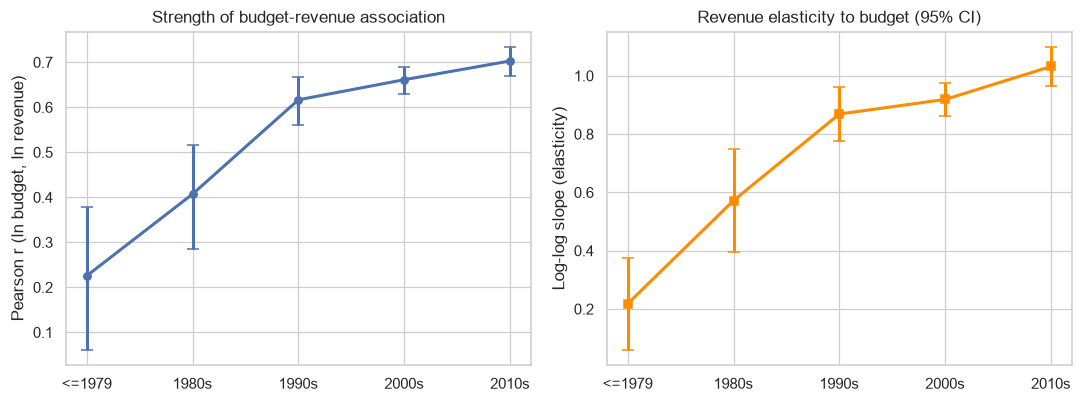

  [figure] fig_correlation_by_era.png

Quick preview of RQ1 interaction (full modelling goes in Section 5):
                            coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                 2.8962      0.506      5.718      0.000       1.904       3.889
ln_budget_real            0.8718      0.029     30.360      0.000       0.816       0.928
year_c                   -0.3435      0.036     -9.635      0.000      -0.413      -0.274
ln_budget_real:year_c     0.0189      0.002      9.183      0.000       0.015       0.023

Return on budget by budget tier (2017 USD):
             films  median_roi  pct_unprofitable   iqr
budget_real                                           
<$10M          482        3.24             27.59  8.84
$10-50M       1440        2.25             26.25  3.46
$50-100M       706        2.02             24.79  2.41
>$100M         511        2.38  

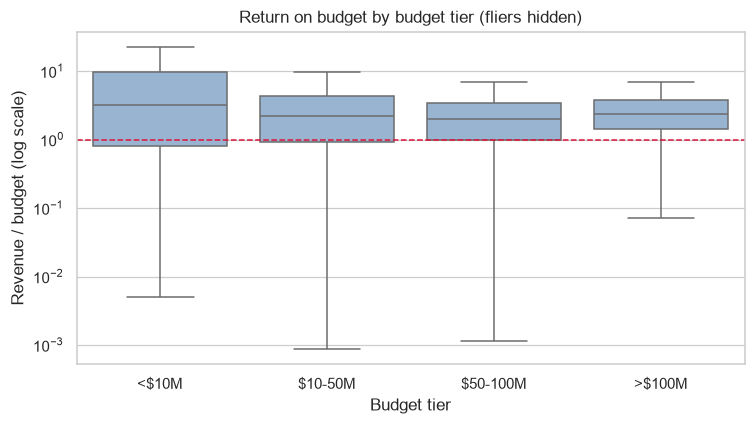

  [figure] fig_roi_by_budget_tier.png


In [10]:
def eda_budget_revenue(an, out):
    header("2.3  EDA - BUDGET vs REVENUE BY ERA (RQ1)")
    eras = [e for e in ERA_ORDER if (an["era"] == e).any()]

    # faceted log-log scatter
    fig, axes = plt.subplots(1, len(eras), figsize=(3.6 * len(eras), 3.9), sharex=True, sharey=True)
    axes = np.atleast_1d(axes)
    for ax, e in zip(axes, eras):
        g = an[an["era"] == e]
        sns.regplot(data=g, x="ln_budget_real", y="ln_revenue_real", ax=ax,
                    scatter_kws={"s": 10, "alpha": 0.35}, line_kws={"color": "crimson"})
        ax.set_title(f"{e} (n={len(g)})")
        ax.set_xlabel("ln budget (2017 USD)")
        ax.set_ylabel("ln revenue (2017 USD)" if ax is axes[0] else "")
    out.savefig("fig_budget_revenue_by_era")

    # correlation / slope by era with CIs
    rows = []
    for e in eras:
        g = an[an["era"] == e]
        r, _ = stats.pearsonr(g["ln_budget_real"], g["ln_revenue_real"])
        rho, _ = stats.spearmanr(g["ln_budget_real"], g["ln_revenue_real"])
        lo, hi = fisher_ci(r, len(g))
        lr = stats.linregress(g["ln_budget_real"], g["ln_revenue_real"])
        rows.append((e, len(g), r, lo, hi, rho, lr.slope, lr.stderr, r ** 2))
    ct = pd.DataFrame(rows, columns=["era", "n", "pearson_r", "ci_lo", "ci_hi", "spearman_rho",
                                     "ols_slope", "slope_se", "r_squared"]).set_index("era")
    say(ct.round(3).to_string())
    out.savetab(ct, "budget_revenue_by_era")

    fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
    axes[0].errorbar(ct.index, ct["pearson_r"], yerr=[ct["pearson_r"] - ct["ci_lo"], ct["ci_hi"] - ct["pearson_r"]],
                     fmt="o-", capsize=4, lw=2)
    axes[0].set_ylabel("Pearson r (ln budget, ln revenue)")
    axes[0].set_title("Strength of budget-revenue association")
    axes[1].errorbar(ct.index, ct["ols_slope"], yerr=1.96 * ct["slope_se"], fmt="s-", color="darkorange", capsize=4, lw=2)
    axes[1].set_ylabel("Log-log slope (elasticity)")
    axes[1].set_title("Revenue elasticity to budget (95% CI)")
    out.savefig("fig_correlation_by_era")

    # preview of the RQ1 interaction: slope by era via year-centred regression
    d = an.assign(year_c=an["release_year"] - an["release_year"].mean())
    m = smf.ols("ln_revenue_real ~ ln_budget_real * year_c", data=d).fit(cov_type="HC3")
    say("\nQuick preview of RQ1 interaction (full modelling goes in Section 5):")
    say(m.summary().tables[1].as_text())

    # ROI distribution by budget tier
    tiers = pd.cut(an["budget_real"], [0, 1e7, 5e7, 1e8, np.inf], labels=["<$10M", "$10-50M", "$50-100M", ">$100M"])
    rt = an.groupby(tiers, observed=True)["roi"].agg(films="size", median_roi="median",
                                                    pct_unprofitable=lambda s: (s < 1).mean() * 100,
                                                    iqr=lambda s: s.quantile(.75) - s.quantile(.25))
    say("\nReturn on budget by budget tier (2017 USD):")
    say(rt.round(2).to_string())
    out.savetab(rt, "roi_by_budget_tier", float_format="%.2f")
    fig, ax = plt.subplots(figsize=(7, 4))
    sns.boxplot(x=tiers, y=an["roi"], ax=ax, showfliers=False, color="#8FB4D9")
    ax.set_yscale("log")
    ax.axhline(1, color="crimson", ls="--", lw=1)
    ax.set_xlabel("Budget tier")
    ax.set_ylabel("Revenue / budget (log scale)")
    ax.set_title("Return on budget by budget tier (fliers hidden)")
    out.savefig("fig_roi_by_budget_tier")


eda_budget_revenue(an, out)

### 6.4 Production scale vs. budget (RQ2)


2.3  EDA - PRODUCTION SCALE vs BUDGET (RQ2)


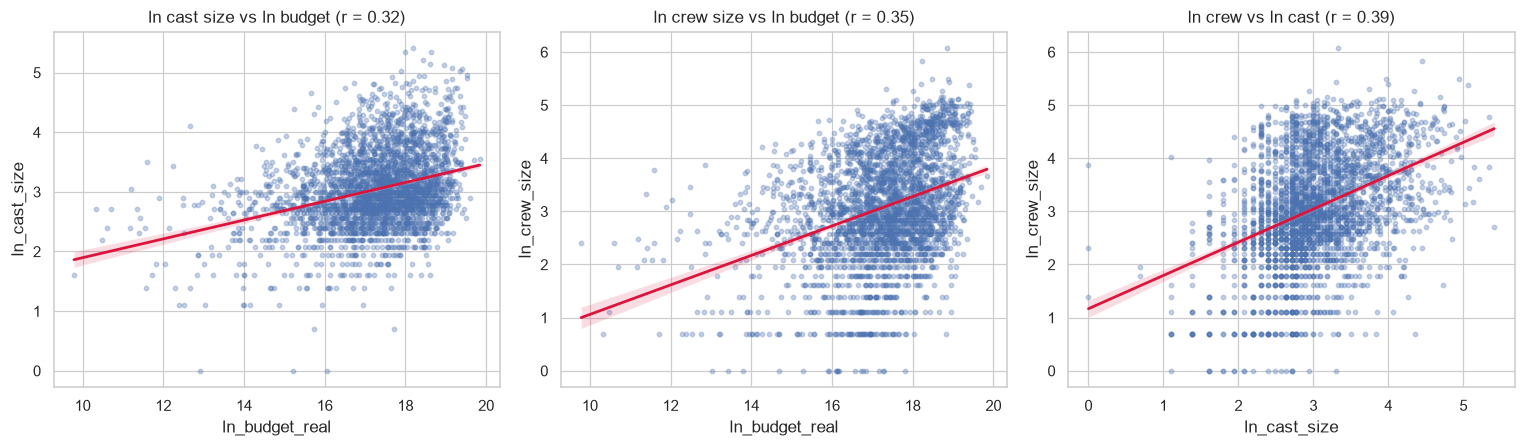

  [figure] fig_scale_vs_budget.png
Does scale carry signal about revenue beyond budget? (partial correlations)
                raw_r_with_ln_revenue  partial_r_given_budget  p_budget  partial_r_given_budget_year  p_budget_year     n
scale_variable                                                                                                           
ln_cast_size                   0.3751                  0.2393       0.0                       0.2543            0.0  3139
ln_crew_size                   0.3795                  0.2199       0.0                       0.2481            0.0  3139
  [table]  partial_correlations.csv

Variance inflation factors (relevant for Lasso/Ridge motivation in RQ2):
ln_budget_real    1.25
ln_cast_size      1.30
ln_crew_size      1.29
release_year      1.06
runtime           1.20
  [table]  vif.csv


In [11]:
def eda_scale_vs_budget(an, out):
    header("2.3  EDA - PRODUCTION SCALE vs BUDGET (RQ2)")
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
    for ax, c, lab in zip(axes[:2], ["ln_cast_size", "ln_crew_size"], ["ln cast size", "ln crew size"]):
        sns.regplot(data=an, x="ln_budget_real", y=c, ax=ax, scatter_kws={"s": 8, "alpha": 0.3}, line_kws={"color": "crimson"})
        r = an[["ln_budget_real", c]].corr().iloc[0, 1]
        ax.set_title(f"{lab} vs ln budget (r = {r:.2f})")
    sns.regplot(data=an, x="ln_cast_size", y="ln_crew_size", ax=axes[2], scatter_kws={"s": 8, "alpha": 0.3}, line_kws={"color": "crimson"})
    r = an[["ln_cast_size", "ln_crew_size"]].corr().iloc[0, 1]
    axes[2].set_title(f"ln crew vs ln cast (r = {r:.2f})")
    out.savefig("fig_scale_vs_budget")

    rows = []
    for c in ["ln_cast_size", "ln_crew_size"]:
        r0 = an[[c, "ln_revenue_real"]].corr().iloc[0, 1]
        rb, pb, n = partial_corr(an, c, "ln_revenue_real", ["ln_budget_real"])
        ry, py, _ = partial_corr(an, c, "ln_revenue_real", ["ln_budget_real", "release_year"])
        rows.append((c, r0, rb, pb, ry, py, n))
    pc = pd.DataFrame(rows, columns=["scale_variable", "raw_r_with_ln_revenue", "partial_r_given_budget", "p_budget",
                                     "partial_r_given_budget_year", "p_budget_year", "n"]).set_index("scale_variable")
    say("Does scale carry signal about revenue beyond budget? (partial correlations)")
    say(pc.round(4).to_string())
    out.savetab(pc, "partial_correlations", float_format="%.4f")

    # multicollinearity preview
    X = an[["ln_budget_real", "ln_cast_size", "ln_crew_size", "release_year", "runtime"]].dropna()
    Xc = np.column_stack([np.ones(len(X)), X.values])
    vif = pd.Series([variance_inflation_factor(Xc, i + 1) for i in range(X.shape[1])], index=X.columns, name="VIF")
    say("\nVariance inflation factors (relevant for Lasso/Ridge motivation in RQ2):")
    say(vif.round(2).to_string())
    out.savetab(vif.to_frame(), "vif", float_format="%.2f")


eda_scale_vs_budget(an, out)

### 6.5 Correlation matrix


2.3  EDA - CORRELATION MATRIX
  [table]  spearman_correlations.csv


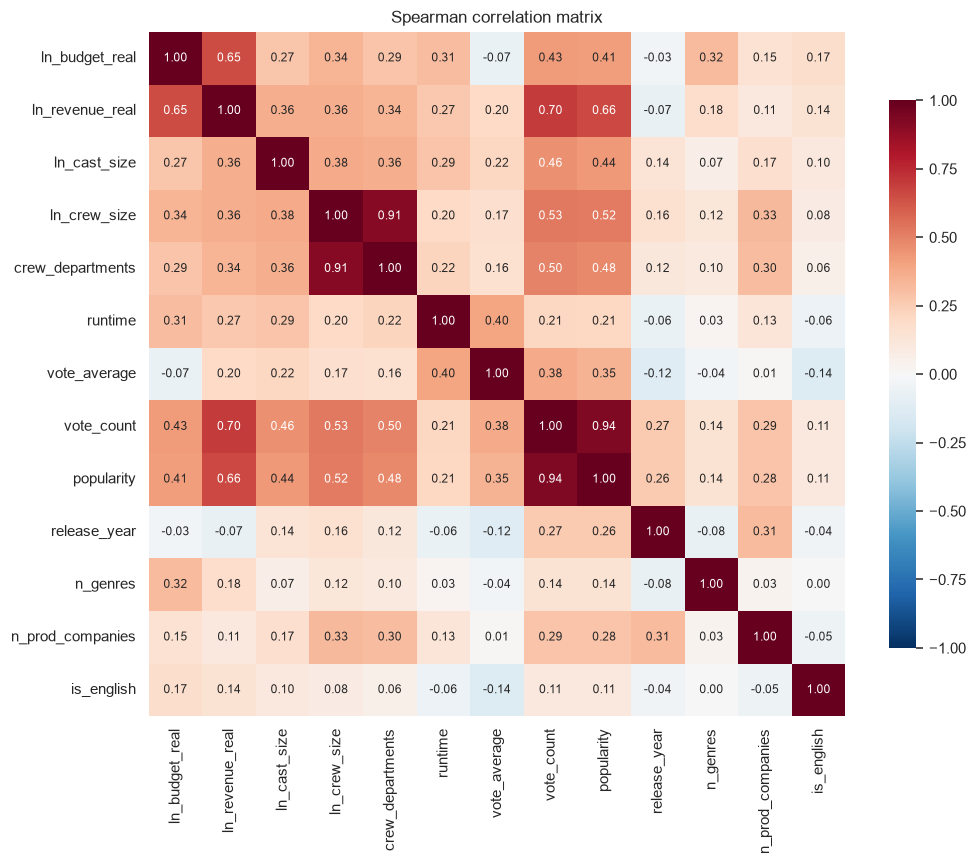

  [figure] fig_correlation_heatmap.png
Spearman correlation with ln revenue (sorted by |rho|):
vote_count          0.697
popularity          0.658
ln_budget_real      0.653
ln_crew_size        0.365
ln_cast_size        0.362
crew_departments    0.340
runtime             0.267
vote_average        0.196
n_genres            0.182
is_english          0.142
n_prod_companies    0.107
release_year       -0.074


In [12]:
def eda_correlations(an, out):
    header("2.3  EDA - CORRELATION MATRIX")
    cols = ["ln_budget_real", "ln_revenue_real", "ln_cast_size", "ln_crew_size", "crew_departments", "runtime",
            "vote_average", "vote_count", "popularity", "release_year", "n_genres", "n_prod_companies", "is_english"]
    cm = an[cols].corr(method="spearman")
    out.savetab(cm, "spearman_correlations", float_format="%.3f")
    fig, ax = plt.subplots(figsize=(9.5, 8))
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax,
                cbar_kws={"shrink": 0.8}, annot_kws={"size": 8})
    ax.set_title("Spearman correlation matrix")
    out.savefig("fig_correlation_heatmap")
    top = cm["ln_revenue_real"].drop("ln_revenue_real").sort_values(key=abs, ascending=False)
    say("Spearman correlation with ln revenue (sorted by |rho|):")
    say(top.round(3).to_string())


eda_correlations(an, out)

### 6.6 Genre


2.3  EDA - GENRE
                 films  median_budget_real  median_revenue_real  median_roi  median_cast  median_crew
genre                                                                                                
Drama             1385         28610894.94         5.795338e+07        2.02         19.0         20.0
Comedy            1089         34584662.58         8.030728e+07        2.30         19.0         16.0
Thriller           925         40323254.78         7.948953e+07        2.17         19.0         26.0
Action             908         64109166.90         1.236738e+08        2.16         21.0         26.5
Adventure          653         81745414.12         1.902759e+08        2.38         22.0         26.0
Romance            544         30139802.77         6.525617e+07        2.31         19.0         16.0
Crime              516         35427659.21         6.790933e+07        2.00         20.0         22.0
Science Fiction    425         62846153.85         1.157788e+08 

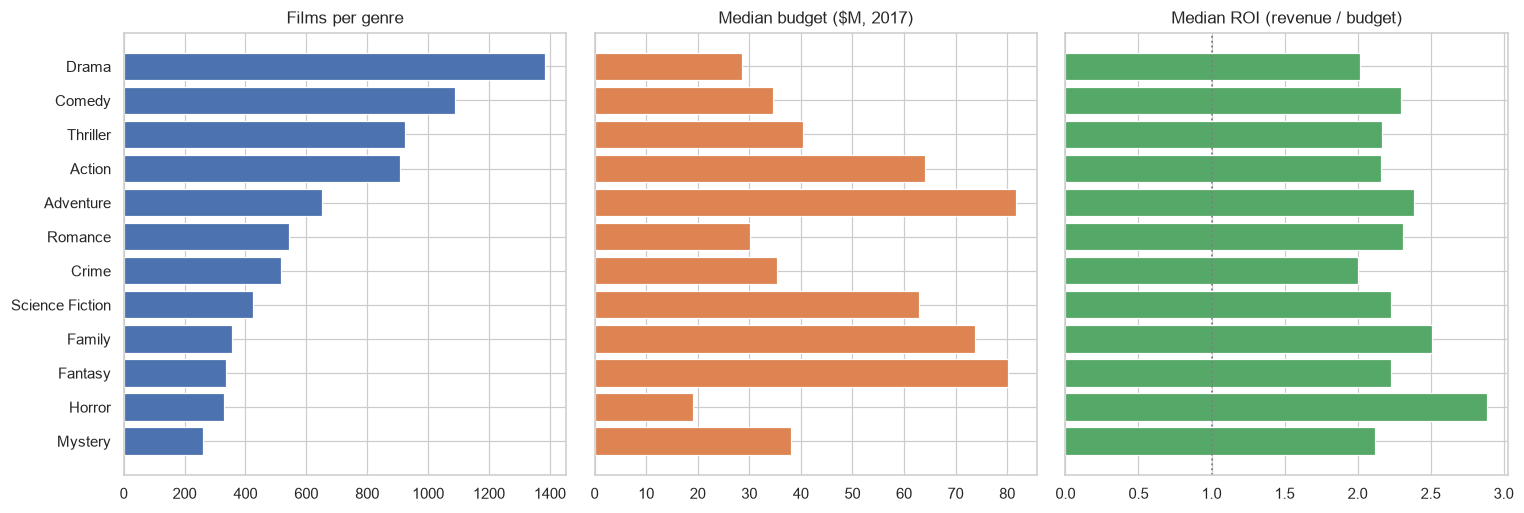

  [figure] fig_genre_summary.png


In [13]:
def eda_genre(an, out):
    header("2.3  EDA - GENRE")
    ex = an.explode("genres_list").rename(columns={"genres_list": "genre"})
    ex = ex[ex["genre"].notna()]
    g = ex.groupby("genre").agg(films=("title", "size"), median_budget_real=("budget_real", "median"),
                                median_revenue_real=("revenue_real", "median"), median_roi=("roi", "median"),
                                median_cast=("cast_size", "median"), median_crew=("crew_size", "median"))
    g = g.sort_values("films", ascending=False)
    say(g.round(2).to_string())
    out.savetab(g, "genre_summary", float_format="%.2f")
    top = g.head(12)
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.8), sharey=True)
    order = top.index.tolist()
    axes[0].barh(order, top["films"], color="#4C72B0")
    axes[0].set_title("Films per genre")
    axes[1].barh(order, top["median_budget_real"] / 1e6, color="#DD8452")
    axes[1].set_title("Median budget ($M, 2017)")
    axes[2].barh(order, top["median_roi"], color="#55A868")
    axes[2].axvline(1, color="grey", ls=":")
    axes[2].set_title("Median ROI (revenue / budget)")
    axes[0].invert_yaxis()
    out.savefig("fig_genre_summary")


eda_genre(an, out)

### 6.7 Awards: nomination and win stages (RQ4)


2.3  EDA - AWARDS (RQ4)
                        stage    n     rate
                    All films 3139      NaN
   Nominated (>=1 nomination)  747 0.237974
Won (>=1 win) among nominated  300 0.401606
  [table]  awards_class_balance.csv
Budget quartile edges ($M, 2017): 0.0, 16.9, 37.1, 75.3, 414.1
  [table]  awards_nomination_by_budget_quartile.csv

P(nominated) by budget quartile:
                n  events   rate  ci_lo  ci_hi
budget_q                                      
Q1 (lowest)   788     152  0.193  0.167  0.222
Q2            782     158  0.202  0.175  0.232
Q3            786     183  0.233  0.205  0.264
Q4 (highest)  783     254  0.324  0.293  0.358
  [table]  awards_win_by_budget_quartile.csv

P(win | nominated) by budget quartile:
                n  events   rate  ci_lo  ci_hi
budget_q                                      
Q1 (lowest)   152      65  0.428  0.352  0.507
Q2            158      71  0.449  0.374  0.527
Q3            183      74  0.404  0.336  0.477
Q4 (highest)

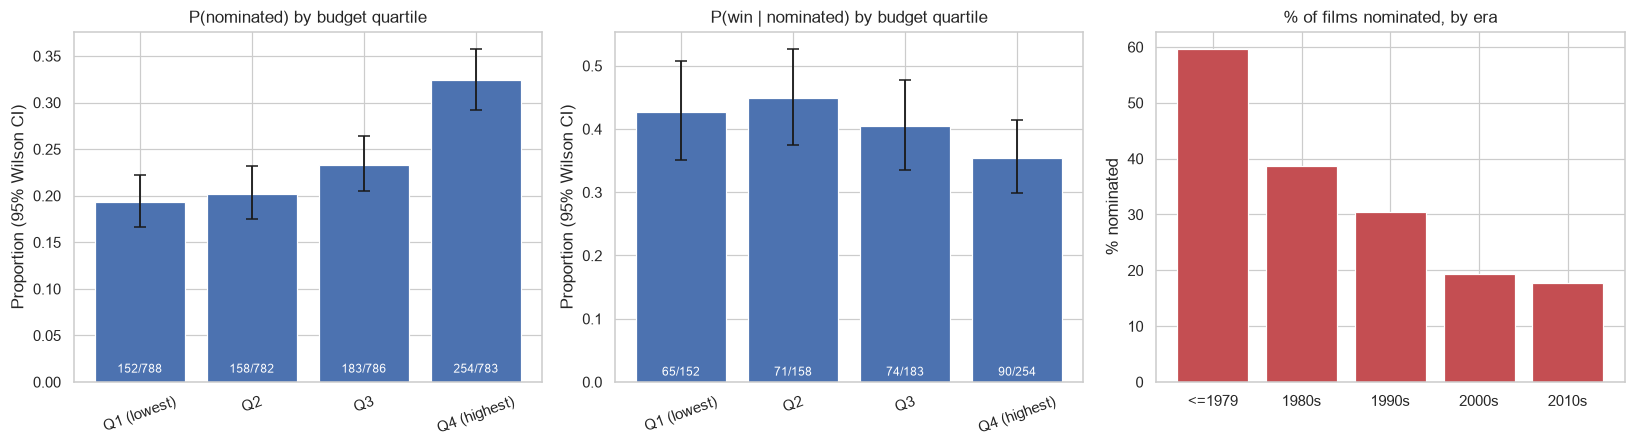

  [figure] fig_awards_by_budget_quartile.png

Chi-square test (budget quartile x nominated): chi2=46.76, p=3.911e-10


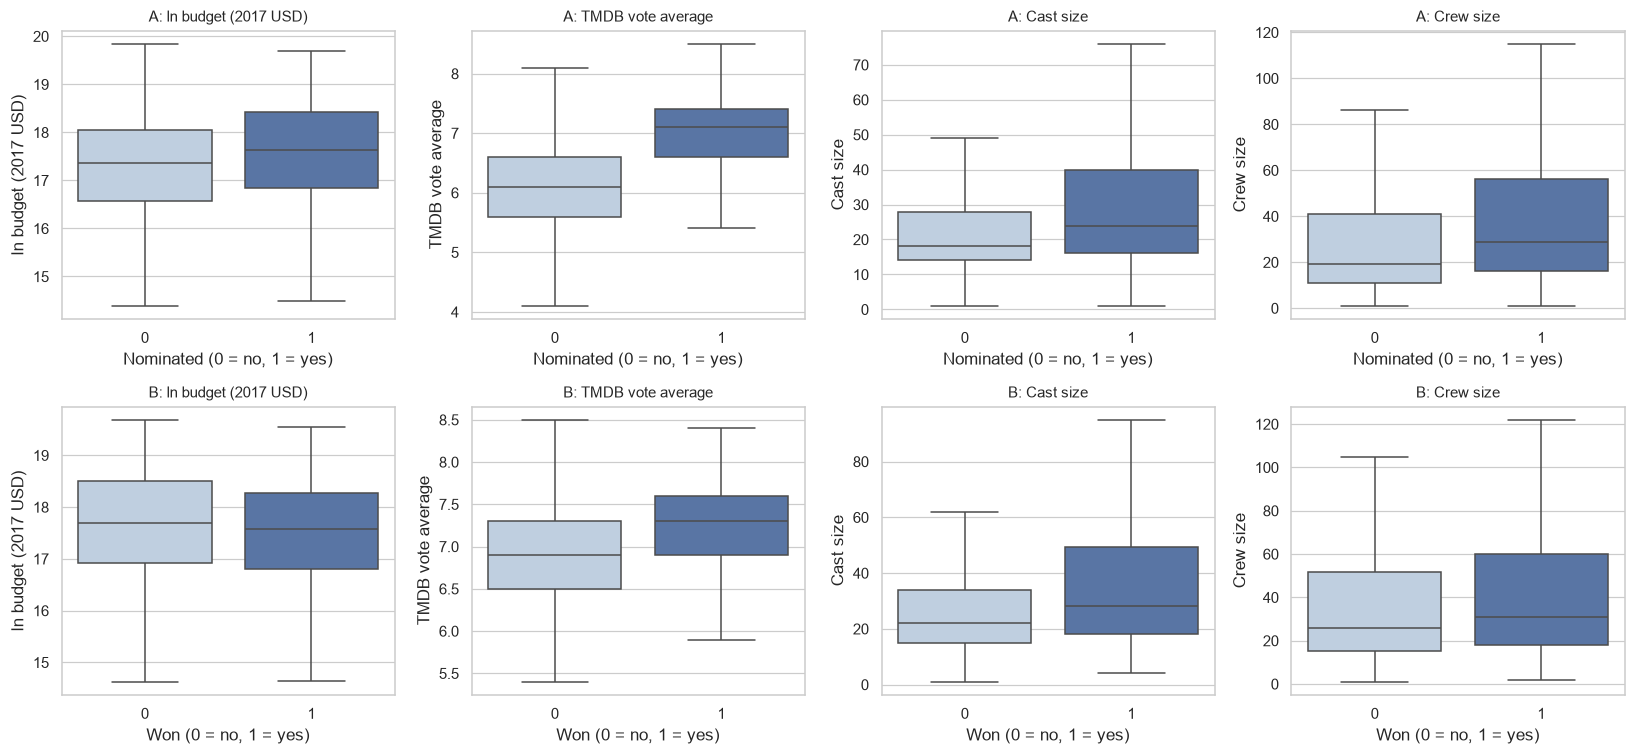

  [figure] fig_awards_distributions.png

Mann-Whitney tests:
                         stage       variable  n_group0  n_group1  median_group0  median_group1  mannwhitney_p
           A: nominated vs not ln_budget_real      2392       747        17.3603        17.6333         0.0000
           A: nominated vs not   vote_average      2392       747         6.1000         7.1000         0.0000
           A: nominated vs not      cast_size      2392       747        18.0000        24.0000         0.0000
           A: nominated vs not      crew_size      2392       747        19.0000        29.0000         0.0000
B: won vs lost (nominees only) ln_budget_real       447       300        17.6998        17.5708         0.0948
B: won vs lost (nominees only)   vote_average       447       300         6.9000         7.3000         0.0000
B: won vs lost (nominees only)      cast_size       447       300        22.0000        28.0000         0.0000
B: won vs lost (nominees only)      crew_size      

In [14]:
def eda_awards(an, out):
    header("2.3  EDA - AWARDS (RQ4)")
    n, nn, nw = len(an), int(an["nominated"].sum()), int(an["won"].sum())
    cb = pd.DataFrame({
        "stage": ["All films", "Nominated (>=1 nomination)", "Won (>=1 win) among nominated"],
        "n": [n, nn, nw],
        "rate": [np.nan, nn / n, nw / nn if nn else np.nan]})
    say(cb.to_string(index=False))
    out.savetab(cb, "awards_class_balance", index=False)
    if nw < 30:
        say(f"  !! Only {nw} winners among {nn} nominees -- the win-stage model will have low power. "
            "Consider regularisation / Firth logistic and report CIs.")

    # quartiles of real budget
    labels = ["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"]
    an["budget_q"] = pd.qcut(an["budget_real"], 4, labels=labels)
    edges = an["budget_real"].quantile([0, .25, .5, .75, 1.0]).values / 1e6
    say("Budget quartile edges ($M, 2017): " + ", ".join(f"{e:.1f}" for e in edges))

    stage_a = an.groupby("budget_q", observed=True)["nominated"].agg(n="size", events="sum")
    nom = an[an["nominated"] == 1]
    stage_b = nom.groupby("budget_q", observed=True)["won"].agg(n="size", events="sum")
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
    tabs = {}
    for ax, (nm, t, ttl) in zip(axes[:2], [("nomination", stage_a, "P(nominated) by budget quartile"),
                                           ("win", stage_b, "P(win | nominated) by budget quartile")]):
        t = t.copy()
        t["rate"] = t["events"] / t["n"].replace(0, np.nan)
        ci = [proportion_confint(e, k, method="wilson") if k > 0 else (np.nan, np.nan) for e, k in zip(t["events"], t["n"])]
        t["ci_lo"], t["ci_hi"] = [c[0] for c in ci], [c[1] for c in ci]
        tabs[nm] = t
        ax.bar(t.index.astype(str), t["rate"], yerr=[t["rate"] - t["ci_lo"], t["ci_hi"] - t["rate"]],
               color="#4C72B0", capsize=4)
        for i, (k, e) in enumerate(zip(t["n"], t["events"])):
            ax.text(i, 0.01, f"{int(e)}/{int(k)}", ha="center", color="white", fontsize=8)
        ax.set_title(ttl)
        ax.set_ylabel("Proportion (95% Wilson CI)")
        ax.tick_params(axis="x", rotation=20)
        out.savetab(t, f"awards_{nm}_by_budget_quartile")
        say(f"\n{ttl}:")
        say(t.round(3).to_string())

    # nomination rate by era (confounding with time)
    era_t = an.groupby("era", observed=True)["nominated"].mean() * 100
    axes[2].bar(era_t.index.astype(str), era_t.values, color="#C44E52")
    axes[2].set_title("% of films nominated, by era")
    axes[2].set_ylabel("% nominated")
    say("\n% nominated by era:")
    say(era_t.round(2).to_string())
    out.savefig("fig_awards_by_budget_quartile")

    chi, p, _, _ = stats.chi2_contingency(pd.crosstab(an["budget_q"], an["nominated"]))
    say(f"\nChi-square test (budget quartile x nominated): chi2={chi:.2f}, p={p:.4g}")

    # distribution comparisons
    vars_ = [("ln_budget_real", "ln budget (2017 USD)"), ("vote_average", "TMDB vote average"),
             ("cast_size", "Cast size"), ("crew_size", "Crew size")]
    fig, axes = plt.subplots(2, 4, figsize=(15, 7))
    rows = []
    for r_i, (stage, data, flag) in enumerate([("A: nominated vs not", an, "nominated"),
                                               ("B: won vs lost (nominees only)", nom, "won")]):
        for c_i, (v, lab) in enumerate(vars_):
            ax = axes[r_i, c_i]
            sns.boxplot(data=data, x=flag, y=v, ax=ax, showfliers=False, palette=["#B9CFE6", "#4C72B0"])
            ax.set_xlabel(("Nominated" if flag == "nominated" else "Won") + " (0 = no, 1 = yes)")
            ax.set_ylabel(lab)
            a, b = data.loc[data[flag] == 0, v].dropna(), data.loc[data[flag] == 1, v].dropna()
            if len(a) > 1 and len(b) > 1:
                u = stats.mannwhitneyu(a, b, alternative="two-sided")
                rows.append((stage, v, len(a), len(b), a.median(), b.median(), u.pvalue))
            ax.set_title(f"{stage.split(':')[0]}: {lab}", fontsize=10)
    out.savefig("fig_awards_distributions")
    mw = pd.DataFrame(rows, columns=["stage", "variable", "n_group0", "n_group1", "median_group0",
                                     "median_group1", "mannwhitney_p"])
    say("\nMann-Whitney tests:")
    say(mw.round(4).to_string(index=False))
    out.savetab(mw, "awards_mannwhitney", index=False, float_format="%.4f")

    # top genres among nominees
    ex = nom.explode("genres_list")
    gt = ex["genres_list"].value_counts().head(8)
    say("\nTop genres among nominated films:")
    say(gt.to_string())


if has_awards:
    eda_awards(an, out)
else:
    print('Oscar file not found, skipping awards EDA.')

## 7. Save analysis-ready dataset & log

In [15]:
drop = ["genres", "keywords", "cast", "crew", "production_companies", "production_countries",
        "spoken_languages", "homepage", "tagline", "overview", "genres_list"]
clean_df = an.drop(columns=[c for c in drop if c in an.columns])
clean_df.to_csv(OUT_DIR / "tmdb_clean.csv", index=False)
(OUT_DIR / "eda_summary.txt").write_text("\n".join(LOG_LINES), encoding="utf-8")
print(f"Saved {OUT_DIR / 'tmdb_clean.csv'} ({len(clean_df):,} rows) and eda_summary.txt")

Saved outputs/tmdb_clean.csv (3,139 rows) and eda_summary.txt


## 8. Export report-ready LaTeX tables
Reads every CSV in `OUT_DIR/tables` and writes an escaped `booktabs` table to `OUT_DIR/tables_tex/` for `\input{}` in the report. Safe to run on its own after the rest of the notebook has been run.

In [16]:
TEX_DIR = OUT_DIR / "tables_tex"
TEX_DIR.mkdir(parents=True, exist_ok=True)

# per-table column formats (tables with long text need wrapped p-columns)
COLFMT = {"data_dictionary": r"p{0.26\textwidth}p{0.46\textwidth}p{0.2\textwidth}"}


def tex_escape(s, underscore=r"\_"):
    s = str(s)
    for a, b in [("\\", r"\textbackslash{}"), ("&", r"\&"), ("%", r"\%"), ("$", r"\$"), ("#", r"\#"),
                 ("_", underscore), ("{", r"\{"), ("}", r"\}"), ("~", r"\textasciitilde{}"), ("^", r"\textasciicircum{}")]:
        s = s.replace(a, b)
    return s.replace("<=", r"$\leq$").replace(">=", r"$\geq$")


def fmt_cell(v):
    if pd.isna(v):
        return ""
    if isinstance(v, (int, np.integer)):
        return f"{v:,}"
    if isinstance(v, (float, np.floating)):
        if v != 0 and abs(v) < 1e-3:
            return f"{v:.1e}"
        return f"{v:,.0f}" if abs(v) >= 1000 else f"{v:.3f}"
    return tex_escape(v)


def csv_to_tex(csv_path):
    df = pd.read_csv(csv_path)
    df.columns = ["" if str(c).startswith("Unnamed") else c for c in df.columns]
    colfmt = COLFMT.get(csv_path.stem, "l" + "r" * (df.shape[1] - 1))
    lines = [r"\begin{tabular}{" + colfmt + "}", r"\toprule",
             " & ".join(tex_escape(c, underscore=" ") for c in df.columns) + r" \\", r"\midrule"]
    for row in df.itertuples(index=False):
        cells = [fmt_cell(v) for v in row]
        if csv_path.stem == "data_dictionary":          # variable names in monospace
            cells[0] = r"\texttt{" + cells[0] + "}"
        lines.append(" & ".join(cells) + r" \\")
    lines += [r"\bottomrule", r"\end{tabular}"]
    return "\n".join(lines)


for p in sorted((OUT_DIR / "tables").glob("*.csv")):
    (TEX_DIR / f"{p.stem}.tex").write_text(csv_to_tex(p), encoding="utf-8")
print(f"Wrote {len(list(TEX_DIR.glob('*.tex')))} tables to {TEX_DIR}")

Wrote 19 tables to outputs/tables_tex
